In [237]:
import pandas as pd
df=pd.read_csv('healthcare/parkinson_disease.csv')
df.tail(10)

,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
746,248,1,0.83110,0.67512,0.42389,347,346,0.005557,0.001413,0.00313,...,3.5398,3.4060,2.5200,2.2957,2.6990,3.2788,3.0250,2.8945,2.7425,1
747,249,1,0.85141,0.78231,0.42890,343,342,0.005628,0.000034,0.00077,...,117.6949,97.7565,52.4362,14.2118,8.5630,13.5210,17.9862,19.3200,16.7182,1
748,249,1,0.79645,0.78772,0.36342,340,339,0.005686,0.000050,0.00084,...,81.7657,46.9118,8.7211,3.8029,3.5360,3.9038,3.5144,4.6629,3.2192,1
749,249,1,0.81171,0.79637,0.32824,336,335,0.005739,0.000041,0.00079,...,71.9877,52.2558,26.1383,8.8848,7.5768,18.2321,28.5223,18.9284,15.5225,1
750,250,0,0.83172,0.57849,0.36017,375,374,0.005147,0.000036,0.00088,...,2.9830,3.3785,3.1691,2.9234,2.5662,2.4621,2.7629,3.0735,5.1190,0
751,250,0,0.80903,0.56355,0.28385,417,416,0.004627,0.000052,0.00064,...,3.0706,3.0190,3.1212,2.4921,3.5844,3.5400,3.3805,3.2003,6.8671,0
752,250,0,0.16084,0.56499,0.59194,415,413,0.004550,0.000220,0.00143,...,1.9704,1.7451,1.8277,2.4976,5.2981,4.2616,6.3042,10.9058,28.4170,0
753,251,0,0.88389,0.72335,0.46815,381,380,0.005069,0.000103,0.00076,...,51.5607,44.4641,26.1586,6.3076,2.8601,2.5361,3.5377,3.3545,5.0424,0
754,251,0,0.83782,0.74890,0.49823,340,339,0.005679,0.000055,0.00092,...,19.1607,12.8312,8.9434,2.2044,1.9496,1.9664,2.6801,2.8332,3.7131,0
755,251,0,0.81304,0.76471,0.46374,340,339,0.005676,0.000037,0.00078,...,62.9927,21.8152,9.2457,4.8555,3.0551,3.0415,4.0116,2.6217,3.1527,0


In [238]:
print(df['class'].value_counts())
num_categories=len(df['class'].value_counts())
print(num_categories) 
# num_categories should match with explode 

class
1    564
0    192
Name: count, dtype: int64
2


<Axes: >

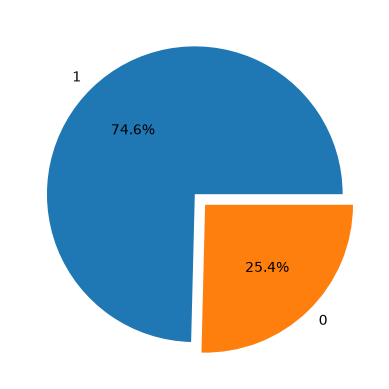

In [239]:
df['class'].value_counts().plot.pie(shadow=False, explode=[0,0.1], autopct='%1.1f%%')

In [240]:
df.isnull().sum().sum()

np.int64(0)

In [241]:
df=df.groupby('id').mean().reset_index()
# every id tested 3 times-> aggregate to create single record per patient
df.tail()
y=df['class']

/var/folders/dk/c9tkhggj5975gx9jxmfq5d7h0000gn/T/ipykernel_5270/1609401287.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df=df.groupby('id').mean().reset_index()


In [242]:
df=df.drop('id',axis=1)
df.shape

(252, 754)

In [243]:
columns=list(df.columns)
for col in columns:
    if col == 'class':
        continue
        # jump to the next outer loop iteration 
    filtered_columns=[col]
    for col1 in df.columns:
        if ((col==col1) | (col1=='class')):
            continue
        corr_val=df[col].corr(df[col1])
        # calculate single correlation coefficient between two columns 
        if corr_val>0.7:
            columns.remove(col1)
            # collinearity 
        else:
            filtered_columns.append(col1)
    df=df[filtered_columns]

In [244]:
print(df.shape)
# num of feature exceeds the number of data points---> feature selection
X=df


(252, 286)


In [245]:
# eliminate redundant and less significant variables
from sklearn.model_selection import train_test_split,GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import (Pipeline as ImbPipeline)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.feature_selection import SelectFdr,SelectKBest,f_classif
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.svm import SVC

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

# placeholder for make_pipeline, Pipeline provide name freedom, make_pipeline must follow auto-generated name
# scaler=MinMaxScaler()
# selector=SelectKBest(score_func=f_classif)

pipe = ImbPipeline([
    # only have fit/transform/fit_transform methods 
    ('scaler', MinMaxScaler()),
    ('sampler',SMOTE(random_state=42)),
    ('selector', SelectKBest(score_func=f_classif)), # Placeholder for feature selection 
    # estimators/models have fit/predict/score methods  
    ('classifier',LogisticRegression())
])
# prevent parameter conflict
param_grid = [
    # Dictionary 1: Search space specifically for SelectKBest
    {
        'scaler': [MinMaxScaler(), StandardScaler()],
        'sampler':[
            SMOTE(sampling_strategy='auto',random_state=42),
            None,
        ],
        'selector': [SelectKBest(score_func=f_classif)],
        'selector__k': [3, 5, 15], # Evaluated ONLY when SelectKBest is active
        'classifier':[SVC(),
                    #   change the loss function(penalty), making a mistake on a minority class sample 3 times costly than making a mistake on a majority class --> easily cause overfitting
                      XGBClassifier(eval_metric='logloss',),
                      LogisticRegression()]
        # logloss: penalty associated with divergence between predicted class probabilities and actual true label to prevent overfitting and early stopping 
        # 0 means flawless model, 0.5 or above means poor performance 
    },
            # 'classifier':[SVC(class_weight='balanced'),
            #         #   change the loss function(penalty), making a mistake on a minority class sample 3 times costly than making a mistake on a majority class --> easily cause overfitting
            #           XGBClassifier(eval_metric='logloss',scale_pos_weight=1/3),
            #           LogisticRegression(class_weight='balanced')]
    
    # Dictionary 2: Search space specifically for SelectFdr
    {
        'scaler': [MinMaxScaler(), StandardScaler()],
        'sampler':[
            SMOTE(sampling_strategy='auto',random_state=42),
            None,
        ],
        'selector': [SelectFdr(score_func=f_classif)],
        'selector__alpha': [0.01, 0.05, 0.1,0.7], # Evaluated ONLY when SelectFdr is active
        'classifier':[SVC(),
                      XGBClassifier(eval_metric='logloss',),
                      LogisticRegression()]
    }
]

stratified_cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
grid_search=GridSearchCV(estimator=pipe,param_grid=param_grid,cv=stratified_cv,scoring='f1')
grid_search.fit(X_train,y_train)

print(f"Best Parameter:{grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.4f}")

Best Parameter:{'classifier': LogisticRegression(), 'sampler': None, 'scaler': MinMaxScaler(), 'selector': SelectFdr(), 'selector__alpha': 0.7}
Best CV score: 0.9029


In [246]:
best_pipeline=grid_search.best_estimator_
print(f"Best estimator:{best_pipeline}")
# X_train_selected=best_pipeline[:-1].transform(X_train)
# cuts off the final model step from the pipeline
fitted_selector=best_pipeline.named_steps['selector']
# extract the chosen feature selection step
feature_mask=fitted_selector.get_support()
# .get_support(): returns an array of booleans[True,False,True] that corresponds to original column index order, identifying exactly which features survived the statistical threshold
selected_columns=X.columns[feature_mask].tolist()
print(len(selected_columns))

Best estimator:Pipeline(steps=[('scaler', MinMaxScaler()), ('sampler', None),
                ('selector', SelectFdr(alpha=0.7)),
                ('classifier', LogisticRegression())])
205


In [247]:
X_selected=X.loc[:,feature_mask]
print(X_selected.shape)
X_selected.tail()

(252, 205)


,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_26,tqwt_kurtosisValue_dec_25,tqwt_kurtosisValue_dec_24,tqwt_kurtosisValue_dec_23,tqwt_kurtosisValue_dec_22,tqwt_kurtosisValue_dec_21,tqwt_kurtosisValue_dec_16,...,meanAutoCorrHarmonicity,locShimmer,locPctJitter,stdDevPeriodPulses,meanPeriodPulses,numPulses,RPDE,DFA,PPE,gender
247,17.0004,13.479700,19.298667,1.552700,1.541600,1.593433,2.264733,2.030533,1.873000,2.189500,...,0.970699,0.057313,0.003193,0.000251,0.005911,326.000000,0.586847,0.651830,0.751703,0.0
248,3.9572,2.880233,4.448533,1.852067,1.993367,2.262400,2.068700,2.109333,2.463633,2.534867,...,0.958578,0.102287,0.002467,0.000964,0.005410,356.666667,0.452343,0.688327,0.611750,1.0
249,16.6743,29.098533,90.482767,1.635000,1.598967,1.594300,1.899467,1.639133,1.622933,3.580000,...,0.994268,0.052500,0.000800,0.000042,0.005684,339.666667,0.373520,0.788800,0.819857,1.0
250,4.1492,2.706000,2.674667,11.502200,2.268800,2.004567,2.384000,3.112900,1.773467,2.009833,...,0.989746,0.026907,0.000983,0.000103,0.004775,402.333333,0.411987,0.569010,0.600530,0.0
251,3.4098,14.782567,44.571367,1.871700,1.637400,1.642800,1.762167,1.982400,1.647533,2.993433,...,0.993396,0.034107,0.000820,0.000065,0.005475,353.666667,0.476707,0.745653,0.844917,0.0


training accuracy:0.9645033112582783
train report:
              precision    recall  f1-score   support

         0.0       0.91      0.64      0.75        50
         1.0       0.89      0.98      0.93       151

    accuracy                           0.90       201
   macro avg       0.90      0.81      0.84       201
weighted avg       0.90      0.90      0.89       201

testing accuracy:0.8706563706563707
test report:
              precision    recall  f1-score   support

         0.0       0.88      0.50      0.64        14
         1.0       0.84      0.97      0.90        37

    accuracy                           0.84        51
   macro avg       0.86      0.74      0.77        51
weighted avg       0.85      0.84      0.83        51



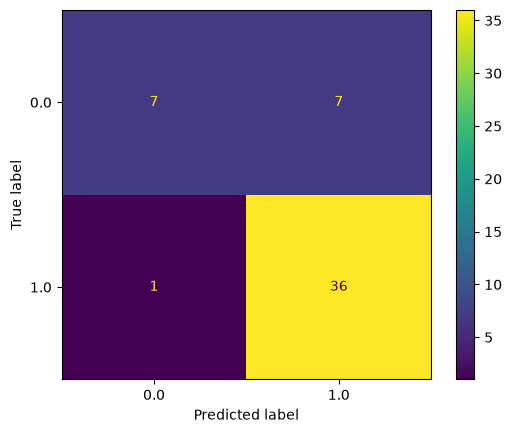

In [250]:
from sklearn.metrics import roc_auc_score as ras
from sklearn.metrics import classification_report,ConfusionMatrixDisplay
train_pred=grid_search.predict(X_train)
# cannot use X_selected, since the grid_search expect 286 columns and containing feature selection inside 
# train_prob=grid_search.predict_proba(X_train)[:,1]
# require SVC(probability=True), can use decision_function instead
train_prob=grid_search.decision_function(X_train)
print(f"training accuracy:{ras(y_train,train_prob)}")
print(f"train report:\n{classification_report(y_train,train_pred)}")
# significant drop of score indicates overfitting
# roc_auc_score is based on continuous probabilities, not for binary predictions
test_pred=grid_search.predict(X_test)
# test_prob=grid_search.predict_proba(X_test)[:,1]
test_prob=grid_search.decision_function(X_test)
print(f"testing accuracy:{ras(y_test,test_prob)}")
print(f"test report:\n{classification_report(y_test,test_pred)}")
ConfusionMatrixDisplay.from_estimator(grid_search,X_test,y_test)